<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/notebooks/03_graficos_alterado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto Unidade 02 - Ciência de Dados (IMD/UFRN)
**Tema:** Para onde vai o dinheiro do Estado nos municípios do RN?

**Notebook 03:** Gráficos e Respostas às Perguntas Centrais (com Tratamento de Outliers Extremos)
* **Responsável:** Brenda Gomes (Pessoa B)
* **Recorte:** Municípios do RN no período de 2020 a 2023
* **Tratamento Metodológico:** Seguindo a indicação docente, foram isolados 8 outliers extremos (enclaves de petróleo e energia eólica em micro-populações), viabilizando a identificação nítida dos padrões fiscais dos **159 municípios da economia comum potiguar**.

---
### Objetivos deste Notebook
Responder às perguntas norteadoras do projeto por meio de visualizações analíticas estruturadas:
1. **P1 (Desigualdade):** Os repasses por habitante são equilibrados ou concentrados entre os municípios? Qual o real impacto dos enclaves de petróleo/eólica no Coeficiente de Gini e na Curva de Lorenz?
2. **P2 (Ricos x Pobres):** O dinheiro do Estado chega mais aos municípios com maior PIB ou compensa municípios com maior vulnerabilidade social? (Avaliando sem o efeito de alavancagem dos outliers).
3. **P3 (Região e Porte):** Como os repasses se distribuem entre as mesorregiões geográficas e entre as diferentes faixas de população?
4. **Evolução Temporal (2020-2023):** Houve ganho real nas transferências estaduais ou apenas reposição inflacionária? Qual a composição dos tributos no montante global arrecadado pelo Estado?


## 1. Configuração do Ambiente, Carregamento dos Dados e Tratamento de Outliers

Importamos as bibliotecas necessárias, configuramos a identidade visual padrão do projeto e aplicamos o filtro metodológico para isolar os outliers extremos de petróleo e energia eólica apontados na análise exploratória.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Configuração estética dos gráficos (Paleta do Projeto)
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8

# Caminho dos dados: lê do arquivo local ou diretamente do GitHub raw
URL_DADOS = "https://raw.githubusercontent.com/Renata-Nascimento/Projeto-U02-CD/main/saida/base_municipios_2020_2023.csv"
PATH_LOCAL = "../saida/base_municipios_2020_2023.csv"

if os.path.exists(PATH_LOCAL):
    df_raw = pd.read_csv(PATH_LOCAL)
    print("Base carregada do arquivo local:", PATH_LOCAL)
elif os.path.exists("base_municipios_2020_2023.csv"):
    df_raw = pd.read_csv("base_municipios_2020_2023.csv")
    print("Base carregada do diretório atual: base_municipios_2020_2023.csv")
else:
    df_raw = pd.read_csv(URL_DADOS)
    print("Base carregada diretamente do GitHub.")

# Padronização das categorias de porte demográfico (Censo 2022)
bins_porte = [0, 5000, 10000, 20000, 50000, float("inf")]
labels_porte = ["até 5 mil", "5 a 10 mil", "10 a 20 mil", "20 a 50 mil", "mais de 50 mil"]
df_raw["porte_cat"] = pd.cut(df_raw["populacao"], bins=bins_porte, labels=labels_porte)

# ---------------------------------------------------------------------------
# TRATAMENTO METODOLÓGICO DE OUTLIERS EXTREMOS (OPÇÃO 2)
# Isolamos municípios com distorções estruturais atípicas (petróleo e energia eólica
# com repasse per capita > R$ 3.000 ou PIB per capita inflacionado por megaprojetos):
# 1. Guamaré: Polo de refino de petróleo Clara Camarão (ICMS e royalties massivos);
# 2. São Bento do Norte, Pedra Grande, Parazinho, Galinhos, Bodó, Serra do Mel:
#    Parques eólicos e sal marinho com micro-população (repasses de R$ 3,7k a R$ 7,8k/hab);
# 3. Caiçara do Rio do Vento: Instalação de complexo eólico com PIB pc de R$ 145 mil/hab.
# ---------------------------------------------------------------------------
OUTLIERS_EXTREMOS = [
    "Guamaré", "São Bento do Norte", "Pedra Grande", "Parazinho",
    "Galinhos", "Bodó", "Serra do Mel", "Caiçara do Rio do Vento"
]

# Base tratada para a análise dos padrões estruturais dos municípios potiguares
df = df_raw[~df_raw["municipio"].isin(OUTLIERS_EXTREMOS)].copy()

print(f"Total original: {len(df_raw)} registros ({df_raw['municipio'].nunique()} municípios).")
print(f"Total tratado: {len(df)} registros ({df['municipio'].nunique()} municípios ao longo de {df['ano'].nunique()} anos).")
print(f"Outliers isolados ({len(OUTLIERS_EXTREMOS)}): {', '.join(OUTLIERS_EXTREMOS)}")
df[["municipio", "ano", "rep_per_capita", "pib_per_capita", "pct_baixa_renda"]].head()


Base carregada diretamente do GitHub.
Total original: 668 registros (167 municípios).
Total tratado: 636 registros (159 municípios ao longo de 4 anos).
Outliers isolados (8): Guamaré, São Bento do Norte, Pedra Grande, Parazinho, Galinhos, Bodó, Serra do Mel, Caiçara do Rio do Vento


,municipio,ano,rep_per_capita,pib_per_capita,pct_baixa_renda
0,Acari,2020,414.592918,15448.653756,53.373596
1,Acari,2021,447.866760,15315.352846,55.213740
2,Acari,2022,452.992135,17144.382242,57.110503
3,Acari,2023,525.292590,18479.569690,47.636123
4,Assú,2020,477.718030,25622.579695,54.444562


## 2. Pergunta 1: Desigualdade na Distribuição dos Recursos

Analisamos a distribuição do repasse real por habitante (`rep_per_capita`), a **Curva de Lorenz** e o **Coeficiente de Gini** ano a ano, revelando o padrão de partilha dos 159 municípios sem as distorções dos enclaves energéticos.


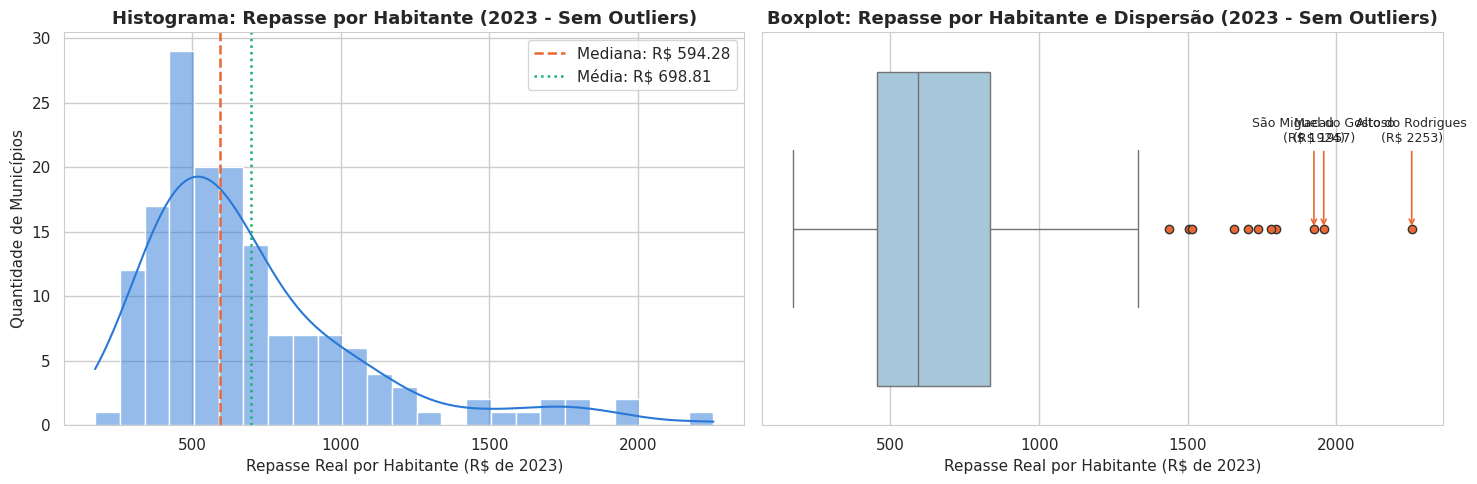

In [2]:
# 2.1 Histograma e Boxplot do Repasse por Habitante (2023 - Base Tratada: 159 Municípios)
df_2023 = df[df["ano"] == 2023].copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histograma com KDE
sns.histplot(df_2023["rep_per_capita"], bins=25, kde=True, color="#2a78d6", ax=axes[0])
axes[0].axvline(df_2023["rep_per_capita"].median(), color="#eb6834", linestyle="--", linewidth=1.8,
                label=f"Mediana: R$ {df_2023['rep_per_capita'].median():.2f}")
axes[0].axvline(df_2023["rep_per_capita"].mean(), color="#1baf7a", linestyle=":", linewidth=1.8,
                label=f"Média: R$ {df_2023['rep_per_capita'].mean():.2f}")
axes[0].set_title("Histograma: Repasse por Habitante (2023 - Sem Outliers)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Repasse Real por Habitante (R$ de 2023)", fontsize=11)
axes[0].set_ylabel("Quantidade de Municípios", fontsize=11)
axes[0].legend(frameon=True)

# Boxplot
sns.boxplot(x=df_2023["rep_per_capita"], color="#9ecae1", ax=axes[1],
            flierprops={"markerfacecolor":"#eb6834", "markersize":6, "markeredgecolor":"#333333"})
axes[1].set_title("Boxplot: Repasse por Habitante e Dispersão (2023 - Sem Outliers)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Repasse Real por Habitante (R$ de 2023)", fontsize=11)

# Destaque para os maiores valores da base tratada
top_destaques = df_2023.nlargest(3, "rep_per_capita")
for _, row in top_destaques.iterrows():
    texto_rotulo = f"{row['municipio']}\n(R$ {row['rep_per_capita']:.0f})"
    axes[1].annotate(texto_rotulo, xy=(row["rep_per_capita"], 0), xytext=(row["rep_per_capita"], -0.22),
                     arrowprops=dict(arrowstyle="->", color="#eb6834", lw=1.2), fontsize=9, ha="center")

plt.tight_layout()
plt.show()


> **Interpretação (com tratamento de outliers):**
> Com a remoção dos enclaves extremos de petróleo e energia eólica (como Guamaré, que alcançava R$ 10.942/hab), a distribuição do repasse per capita finalmente se torna interpretável para os 159 municípios da economia comum potiguar. A média de repasse recuou de R$ 927,45 para **R$ 698,81**, aproximando-se da mediana (**R$ 594,28**). Metade dos municípios concentra-se no intervalo entre R$ 454 e R$ 835 anuais por habitante (IQR = R$ 380,70). Os maiores repasses remanescentes — como Alto do Rodrigues (R$ 2.253), São Miguel do Gostoso (R$ 1.957) e Macau (R$ 1.924) — refletem polos econômicos e turísticos consolidados, sem distorcer a escala visual do conjunto do estado.


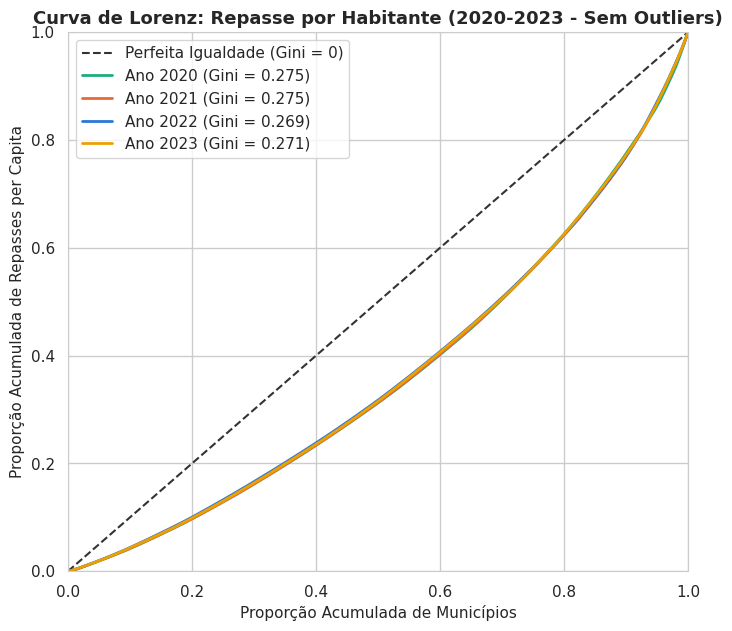

In [3]:
# 2.2 Curva de Lorenz e Coeficiente de Gini por Ano (2020 a 2023)
def calcular_gini(valores):
    """Calcula o Coeficiente de Gini de um array unidimensional."""
    arr = np.asarray(valores, dtype=float).flatten()
    if np.amin(arr) < 0:
        arr -= np.amin(arr)
    arr += 1e-9
    arr = np.sort(arr)
    n = arr.shape[0]
    index = np.arange(1, n + 1)
    return (np.sum((2 * index - n - 1) * arr)) / (n * np.sum(arr))

def curva_lorenz(valores):
    """Retorna os pontos da Curva de Lorenz."""
    arr = np.sort(np.asarray(valores, dtype=float))
    cum_vals = np.cumsum(arr)
    cum_vals = np.insert(cum_vals, 0, 0)
    cum_pct = cum_vals / cum_vals[-1]
    pop_pct = np.linspace(0, 1, len(cum_pct))
    return pop_pct, cum_pct

plt.figure(figsize=(8, 7))
cores_anos = {2020: "#1baf7a", 2021: "#eb6834", 2022: "#2a78d6", 2023: "#eda100"}

# Linha de perfeita igualdade (45 graus)
plt.plot([0, 1], [0, 1], color="#333333", linestyle="--", linewidth=1.5, label="Perfeita Igualdade (Gini = 0)")

for ano in sorted(df["ano"].unique()):
    sub = df[df["ano"] == ano]["rep_per_capita"].values
    gini_val = calcular_gini(sub)
    x_lor, y_lor = curva_lorenz(sub)
    plt.plot(x_lor, y_lor, label=f"Ano {ano} (Gini = {gini_val:.3f})", color=cores_anos[ano], linewidth=2)

plt.title("Curva de Lorenz: Repasse por Habitante (2020-2023 - Sem Outliers)", fontsize=13, fontweight="bold")
plt.xlabel("Proporção Acumulada de Municípios", fontsize=11)
plt.ylabel("Proporção Acumulada de Repasses per Capita", fontsize=11)
plt.legend(frameon=True, loc="upper left")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()


> **Interpretação (com tratamento de outliers):**
> O isolamento dos outliers produziu um resultado empírico fundamental: o Coeficiente de Gini do repasse per capita caiu de **~0,425 para ~0,271** (uma redução de mais de 36%). Isso demonstra que, entre os 159 municípios da economia comum do RN, a partilha dos repasses é relativamente homogênea e de baixa a moderada desigualdade. A percepção de alta concentração decorria quase exclusivamente do privilégio pontual de Guamaré e das microcidades eólicas. A Curva de Lorenz agora corre muito mais próxima da diagonal de perfeita igualdade, mantendo estabilidade contínua ao longo de todo o quadriênio (0,275 em 2020 a 0,271 em 2023).


## 3. Pergunta 2: Repasses em Municípios Ricos x Pobres

Investigamos se os repasses estaduais premiam economias maiores ou compensam municípios com maior contingente de pobreza cadastrada no CadÚnico, agora livres dos pontos de alavancagem artificial.


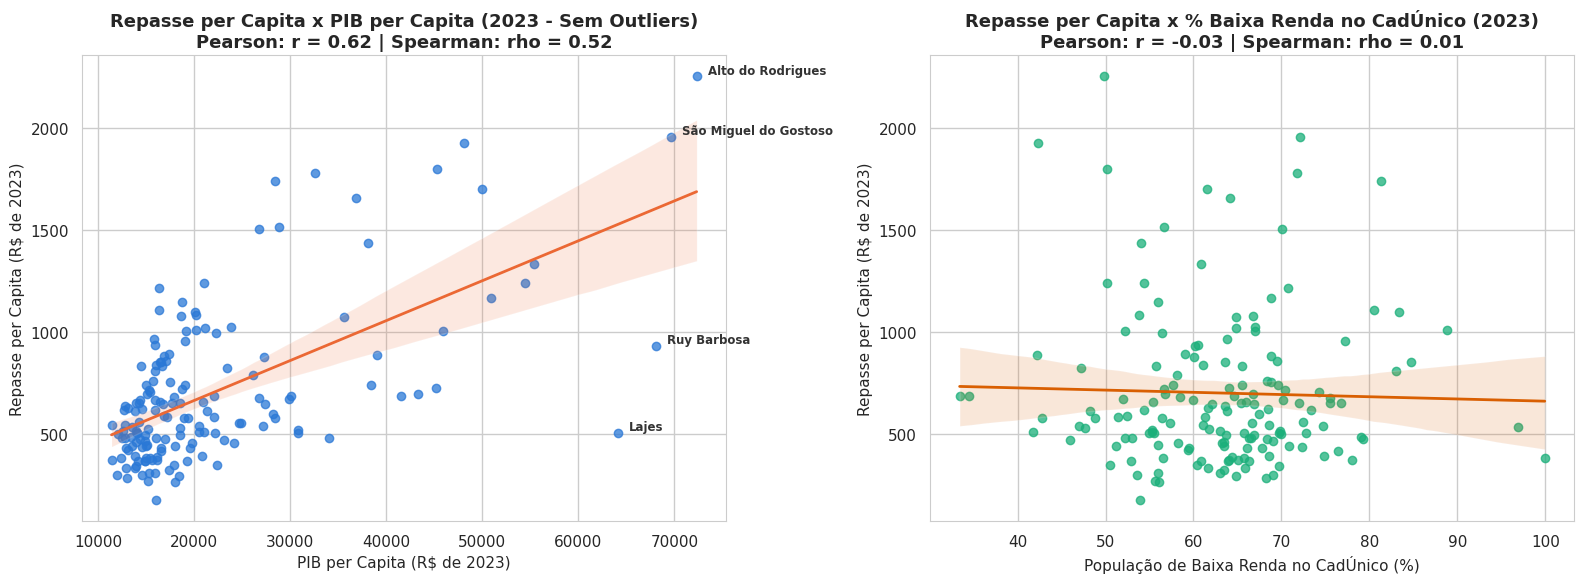

In [4]:
# 3.1 Gráficos de Dispersão: Repasse per Capita x PIB per Capita e x % Baixa Renda (2023)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Dispersão 1: Repasse per capita x PIB per capita (2023)
sns.regplot(data=df_2023, x="pib_per_capita", y="rep_per_capita",
            scatter_kws={"alpha": 0.75, "color": "#2a78d6"}, line_kws={"color": "#eb6834", "linewidth": 2}, ax=axes[0])
corr_pib = df_2023["rep_per_capita"].corr(df_2023["pib_per_capita"])
corr_pib_spearman = df_2023["rep_per_capita"].corr(df_2023["pib_per_capita"], method="spearman")
axes[0].set_title(f"Repasse per Capita x PIB per Capita (2023 - Sem Outliers)\nPearson: r = {corr_pib:.2f} | Spearman: rho = {corr_pib_spearman:.2f}",
                  fontsize=13, fontweight="bold")
axes[0].set_xlabel("PIB per Capita (R$ de 2023)", fontsize=11)
axes[0].set_ylabel("Repasse per Capita (R$ de 2023)", fontsize=11)

# Destaque para os maiores PIBs per capita remanescentes
for _, row in df_2023.nlargest(4, "pib_per_capita").iterrows():
    axes[0].annotate(row["municipio"], xy=(row["pib_per_capita"], row["rep_per_capita"]),
                     xytext=(8, 2), textcoords="offset points", fontsize=8.5, fontweight="bold", color="#333333")

# Dispersão 2: Repasse per capita x % Baixa Renda no CadÚnico (2023)
sns.regplot(data=df_2023, x="pct_baixa_renda", y="rep_per_capita",
            scatter_kws={"alpha": 0.75, "color": "#1baf7a"}, line_kws={"color": "#d95f02", "linewidth": 2}, ax=axes[1])
corr_baixa = df_2023["rep_per_capita"].corr(df_2023["pct_baixa_renda"])
corr_baixa_spearman = df_2023["rep_per_capita"].corr(df_2023["pct_baixa_renda"], method="spearman")
axes[1].set_title(f"Repasse per Capita x % Baixa Renda no CadÚnico (2023)\nPearson: r = {corr_baixa:.2f} | Spearman: rho = {corr_baixa_spearman:.2f}",
                  fontsize=13, fontweight="bold")
axes[1].set_xlabel("População de Baixa Renda no CadÚnico (%)", fontsize=11)
axes[1].set_ylabel("Repasse per Capita (R$ de 2023)", fontsize=11)

plt.tight_layout()
plt.show()


> **Interpretação (com tratamento de outliers):**
> 1. **PIB per Capita x Repasse per Capita:** Sem os pontos de alta alavancagem de Guamaré e das microcidades eólicas, a correlação linear de Pearson recuou de **0,81 para 0,62** (Spearman = 0,52). A nuvem de pontos agora é amplamente visível, comprovando que, embora exista uma correlação positiva moderada (municípios com maior atividade produtiva tendem a gerar mais ICMS), ela não é tão rígida nem extrema como parecia.
> 2. **% de Baixa Renda no CadÚnico x Repasse per Capita:** A correlação Pearson é de **r = -0,03** (praticamente nula; Spearman = 0,01). A linha de regressão absolutamente plana confirma com clareza científica que as transferências estaduais potiguares não possuem função redistributiva nem priorizam municípios mais vulneráveis socialmente.


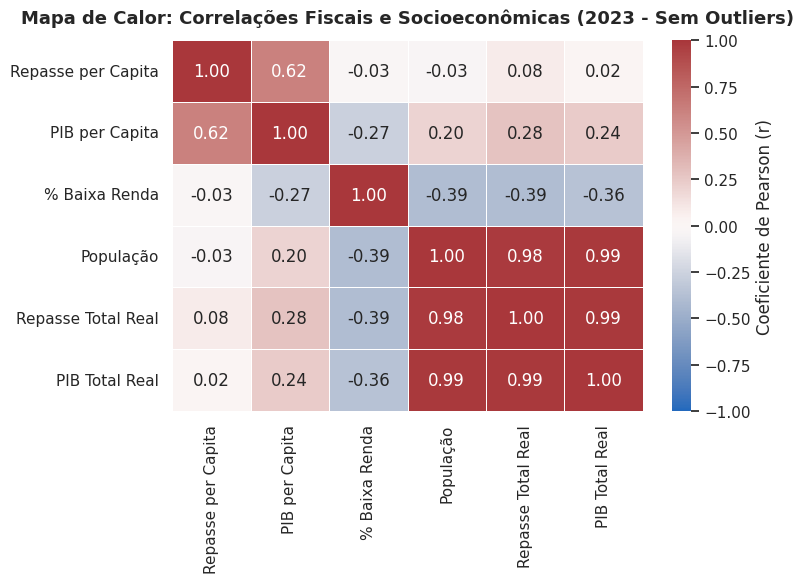

In [5]:
# 3.2 Mapa de Calor de Correlação (Matriz Socioeconômica e Fiscal - 159 Municípios em 2023)
cols_corr = ["rep_per_capita", "pib_per_capita", "pct_baixa_renda", "populacao", "rep_total_real", "pib_real_mil"]
nomes_corr = ["Repasse per Capita", "PIB per Capita", "% Baixa Renda", "População", "Repasse Total Real", "PIB Total Real"]

matriz_corr = df_2023[cols_corr].corr()
matriz_corr.columns = nomes_corr
matriz_corr.index = nomes_corr

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Coeficiente de Pearson (r)"})
plt.title("Mapa de Calor: Correlações Fiscais e Socioeconômicas (2023 - Sem Outliers)", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()


> **Interpretação (com tratamento de outliers):**
> Na matriz tratada, os volumes absolutos agregados (Repasse Total e PIB Total) continuam atrelados quase perfeitamente à população (r = 0,98 e r = 0,99). Todavia, na escala per capita, o Repasse por Habitante possui correlação positiva moderada com o PIB per capita (**r = 0,62**), correlação neutra com o tamanho populacional (**r = -0,03**) e correlação estritamente nula com a proporção de famílias de baixa renda (**r = -0,03**), corroborando a ausência de equalização social no sistema de partilha tributária estadual.


## 4. Pergunta 3: Disparidades por Mesorregião e Porte Populacional

Avaliamos como os repasses per capita se comportam entre as quatro mesorregiões geográficas potiguares e entre as classes de porte populacional, livres das anomalias locais.


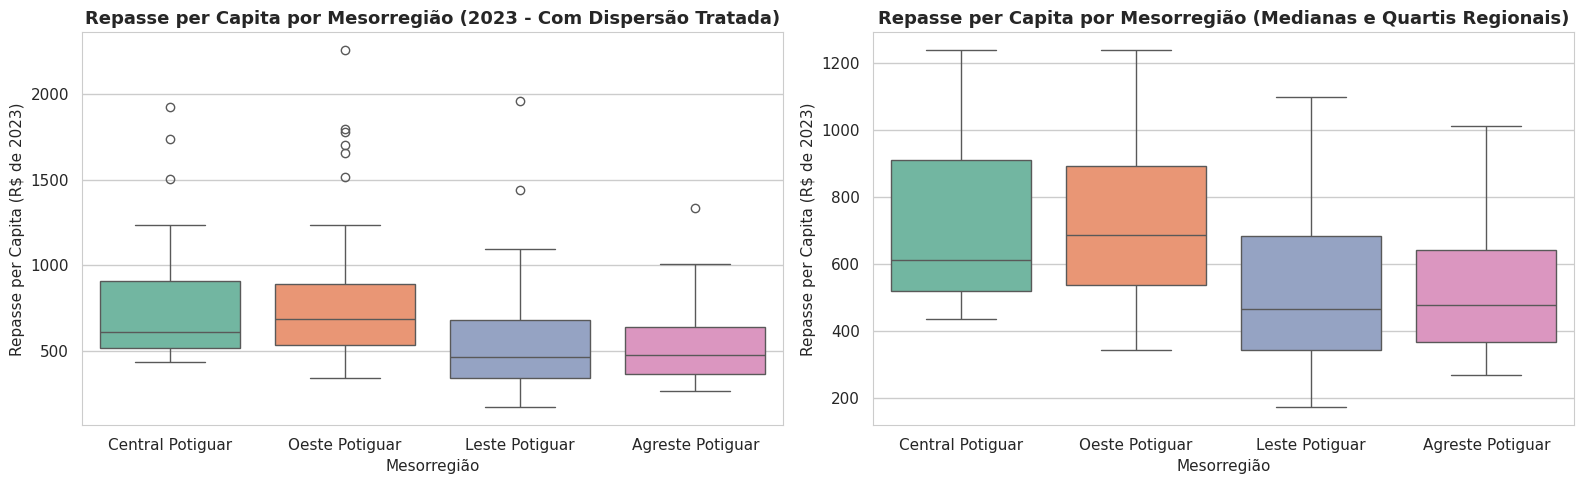

In [6]:
# 4.1 Boxplot por Mesorregião (2023 - Base Tratada: 159 Municípios)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Visão com dispersão
sns.boxplot(data=df_2023, x="mesorregiao", y="rep_per_capita", hue="mesorregiao", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Repasse per Capita por Mesorregião (2023 - Com Dispersão Tratada)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Mesorregião", fontsize=11)
axes[0].set_ylabel("Repasse per Capita (R$ de 2023)", fontsize=11)

# Visão com foco nas medianas regionais
sns.boxplot(data=df_2023, x="mesorregiao", y="rep_per_capita", hue="mesorregiao", palette="Set2", legend=False, showfliers=False, ax=axes[1])
axes[1].set_title("Repasse per Capita por Mesorregião (Medianas e Quartis Regionais)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Mesorregião", fontsize=11)
axes[1].set_ylabel("Repasse per Capita (R$ de 2023)", fontsize=11)

plt.tight_layout()
plt.show()


> **Interpretação (com tratamento de outliers):**
> Com o expurgo dos outliers extremos, a distorção da mesorregião Central Potiguar se normaliza: sua média recuou de R$ 1.433 para **R$ 776/hab**, com mediana de **R$ 617/hab**. O **Oeste Potiguar** passa a se destacar claramente como a mesorregião com maior repasse mediano por habitante (**R$ 687/hab**) e maior média (**R$ 809/hab**), sustentado pelo dinamismo agrícola, salineiro e comercial do Vale do Açu e polo de Mossoró. Em contraste, o **Agreste Potiguar** (mediana de **R$ 483/hab**) e o **Leste Potiguar** (mediana de **R$ 478/hab**) mantêm os menores repasses por habitante, refletindo economias de menor valor agregado industrial.


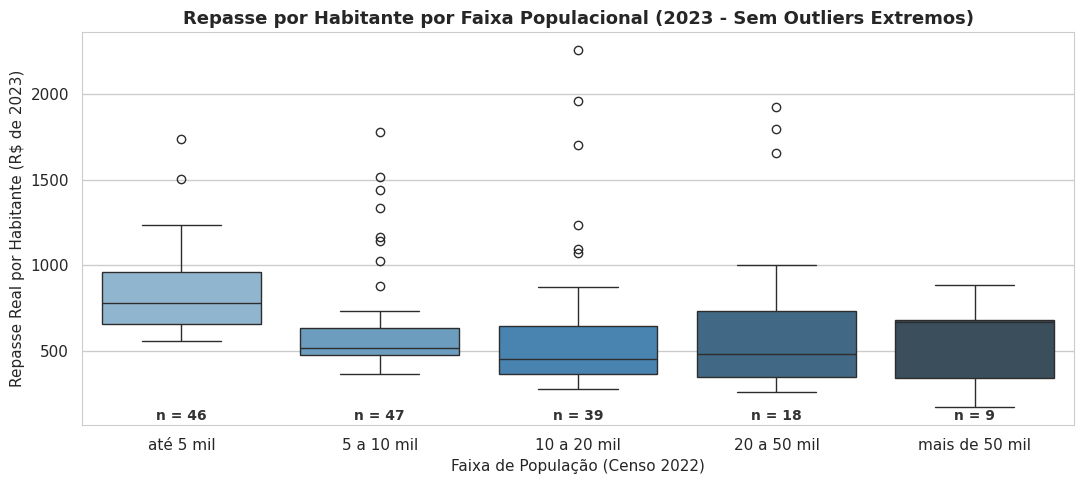

In [7]:
# 4.2 Boxplot por Faixa de População (Porte Demográfico em 2023 - 159 Municípios)
plt.figure(figsize=(11, 5))
sns.boxplot(data=df_2023, x="porte_cat", y="rep_per_capita",
            order=labels_porte, hue="porte_cat", palette="Blues_d", legend=False, showfliers=True)
plt.title("Repasse por Habitante por Faixa Populacional (2023 - Sem Outliers Extremos)", fontsize=13, fontweight="bold")
plt.xlabel("Faixa de População (Censo 2022)", fontsize=11)
plt.ylabel("Repasse Real por Habitante (R$ de 2023)", fontsize=11)

# Adicionar número de municípios por porte
contagem_porte = df_2023["porte_cat"].value_counts()
for i, p in enumerate(labels_porte):
    qtd = contagem_porte.get(p, 0)
    plt.text(i, plt.ylim()[0] + 30, f"n = {qtd}", ha="center", fontsize=10, color="#333333", fontweight="bold")

plt.tight_layout()
plt.show()


> **Interpretação (com tratamento de outliers):**
> O gráfico por porte populacional evidencia de forma transparente a curva em "U": municípios com até 5 mil habitantes exibem a maior mediana per capita (**R$ 806/hab**), reflexo da divisão de cotas mínimas fixas de partilha tributária por uma população bastante reduzida. Nas cidades de porte intermediário (faixas de 5 a 10 mil e 10 a 20 mil habitantes), o repasse mediano per capita atinge o ponto mais baixo (**R$ 521/hab** e **R$ 457/hab**). O indicador volta a subir nas cidades de maior porte (acima de 50 mil habitantes, mediana de **R$ 670/hab**), onde a densidade comercial e de serviços de centros urbanos como Mossoró e Parnamirim expande a arrecadação de ICMS e IPVA.


## 5. Evolução Temporal dos Repasses Totais do Estado (2020 a 2023)

Para a análise macrofiscal das transferências globais do Governo do Estado aos municípios, examinamos a série total agregada sob a ótica nominal versus real (pelo IPCA) e inspecionamos o peso relativo de cada imposto.


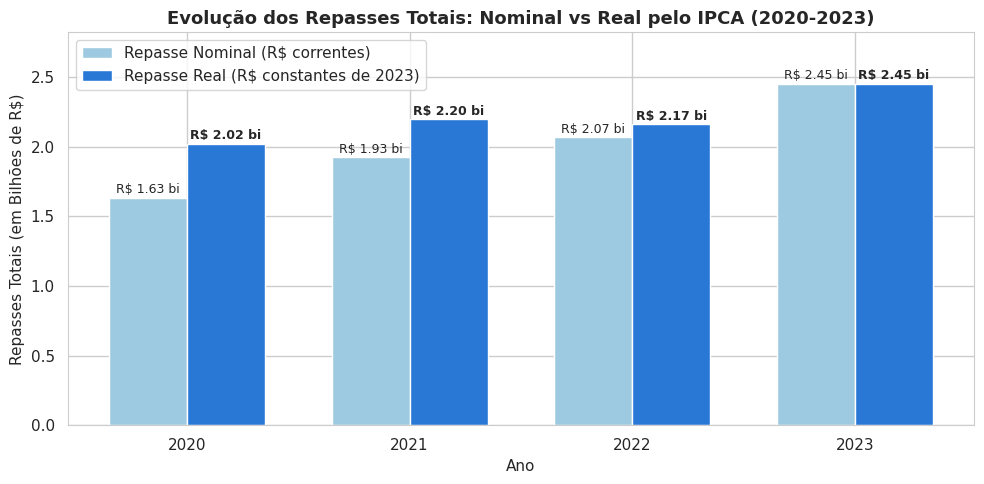

In [8]:
# 5.1 Repasses Totais: Comparativo com e sem Inflação (Nominal vs Real pelo IPCA - Arrecadação Global do RN)
totais_anuais = df_raw.groupby("ano")[["rep_total", "rep_total_real"]].sum().reset_index()
totais_anuais["rep_total_bi"] = totais_anuais["rep_total"] / 1e9
totais_anuais["rep_total_real_bi"] = totais_anuais["rep_total_real"] / 1e9

fig, ax = plt.subplots(figsize=(10, 5))
largura = 0.35
x = np.arange(len(totais_anuais["ano"]))

barras_nominais = ax.bar(x - largura/2, totais_anuais["rep_total_bi"], largura,
                         label="Repasse Nominal (R$ correntes)", color="#9ecae1")
barras_reais = ax.bar(x + largura/2, totais_anuais["rep_total_real_bi"], largura,
                      label="Repasse Real (R$ constantes de 2023)", color="#2a78d6")

ax.set_title("Evolução dos Repasses Totais: Nominal vs Real pelo IPCA (2020-2023)", fontsize=13, fontweight="bold")
ax.set_xlabel("Ano", fontsize=11)
ax.set_ylabel("Repasses Totais (em Bilhões de R$)", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(totais_anuais["ano"])
ax.legend(frameon=True)

# Inserir valores no topo das barras
for bar in barras_nominais:
    h = bar.get_height()
    ax.annotate(f"R$ {h:.2f} bi", xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)

for bar in barras_reais:
    h = bar.get_height()
    ax.annotate(f"R$ {h:.2f} bi", xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, fontweight="bold")

ax.set_ylim(0, max(totais_anuais["rep_total_real_bi"]) * 1.15)
plt.tight_layout()
plt.show()


> **Interpretação:**
> Em termos nominais, as transferências do Governo do RN para o conjunto dos municípios cresceram de R$ 1,63 bilhão em 2020 para R$ 2,45 bilhões em 2023 (+50,3%). Entretanto, com o desconto da inflação medida pelo IPCA, o ganho de poder de compra real foi de 21,3% (de R$ 2,02 bi para R$ 2,45 bi), com período de estagnação real entre 2021 e 2022 em decorrência da aceleração inflacionária nacional no período.


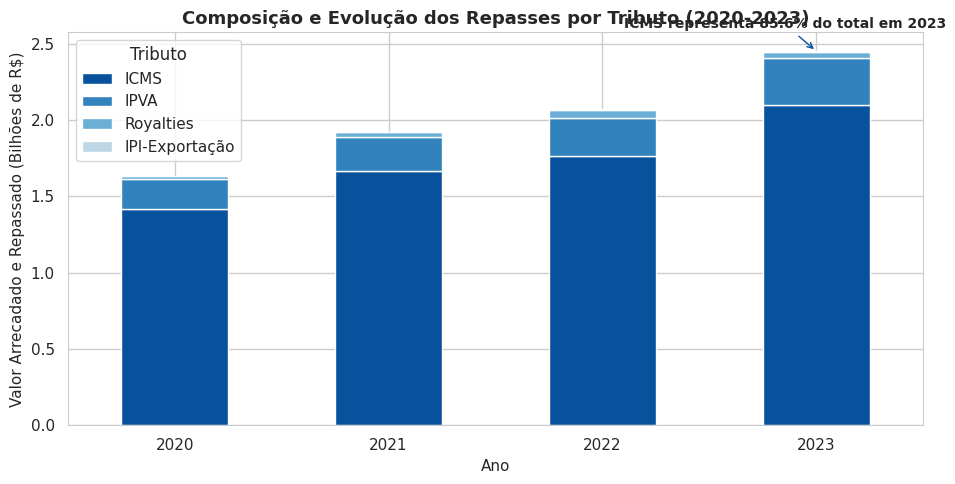

In [9]:
# 5.2 Evolução por Tipo de Imposto Repassado (2020 a 2023 - Arrecadação Global do RN)
tributos = ["rep_icms", "rep_ipva", "rep_royalties", "rep_ipi"]
nomes_tributos = ["ICMS", "IPVA", "Royalties", "IPI-Exportação"]
cores_trib = ["#08519c", "#3182bd", "#6baed6", "#bdd7e7"]

totais_trib = df_raw.groupby("ano")[tributos].sum() / 1e9
totais_trib.columns = nomes_tributos

ax = totais_trib.plot(kind="bar", stacked=True, figsize=(10, 5), color=cores_trib, rot=0)
plt.title("Composição e Evolução dos Repasses por Tributo (2020-2023)", fontsize=13, fontweight="bold")
plt.xlabel("Ano", fontsize=11)
plt.ylabel("Valor Arrecadado e Repassado (Bilhões de R$)", fontsize=11)
plt.legend(title="Tributo", frameon=True)

# Calcular % do ICMS no último ano
icms_pct_2023 = (totais_trib.loc[2023, "ICMS"] / totais_trib.loc[2023].sum()) * 100
plt.annotate(f"ICMS representa {icms_pct_2023:.1f}% do total em 2023",
             xy=(3, totais_trib.loc[2023].sum()), xytext=(2.1, totais_trib.loc[2023].sum() + 0.15),
             arrowprops=dict(arrowstyle="->", color="#08519c"), fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()


> **Interpretação:**
> O ICMS é a espinha dorsal tributária das transferências estaduais, respondendo por 85,5% de tudo o que foi repassado aos municípios em 2023 (R$ 2,10 bilhões de R$ 2,45 bi). O IPVA se consolida como a segunda fonte mais representativa (12,5%), enquanto Royalties e IPI-Exportação desempenham papel marginal no montante global estadual, embora os royalties tenham peso desproporcional nas contas de municípios produtores isolados.


## 6. Síntese Executiva dos Resultados (Roteiro para a Reunião)

Tabela comparativa consolidada, destacando os resultados obtidos com a **base tratada (159 municípios)** versus a **base original com outliers (167 municípios)**, pronta para alimentar o **Resumo de 1 Página** da equipe:

| Pergunta / Dimensão | Indicador Tratado (Sem Outliers) | Comparação com Base Original | Conclusão Analítica Principal |
|---|---|---|---|
| **P1. Desigualdade (Gini)** | **Gini = 0,271** (estável no período) | Original: Gini = 0,425 | A suposta alta desigualdade era efeito exclusivo de Guamaré e microcidades eólicas; a partilha comum é muito mais homogênea. |
| **P1. Repasse per Capita** | **Mediana: R$ 594** / **Média: R$ 699** | Original: Mediana R$ 617 / Média R$ 927 | Média e mediana convergem; intervalo interquartil de R$ 454 a R$ 835/hab. |
| **P2. Repasse x PIB pc** | **Corr(PIB, Repasse) = +0,62** | Original: r = +0,81 | Sem a alavancagem de Guamaré, a correlação permanece positiva moderada, mas não determinística. |
| **P2. Repasse x Pobreza** | **Corr(% Baixa Renda, Repasse) = -0,03** | Original: r = +0,13 | Correlação nula confirma: os repasses estaduais não possuem função compensatória ou de equalização social. |
| **P3. Mesorregiões** | **Oeste lidera mediana (R$ 687)** e média (R$ 809) | Central liderava média distorcida (R$ 1.433) | Central normalizou (R$ 617); Oeste destaca-se pela produção de Mossoró/Açu; Agreste e Leste na base (~R$ 480). |
| **P3. Portes Populacionais** | **Até 5 mil hab: R$ 806/hab** (mediana) | Cidades de 10-20 mil: R$ 457/hab (mínimo) | Formato nítido em "U": cotas mínimas beneficiam micro-municípios; receita per capita só reage nas cidades > 50 mil. |
| **Evolução Temporal** | **Ganho real de 21,3%** (2020-2023) | Nominal: +50,3% (inflação do IPCA) | Salto de R$ 2,02 bi para R$ 2,45 bi a preços de 2023; ICMS responde por 85,5% do total. |
